# ocr-labins-index.ipynb

This file runs OCR on every page of the LABINS volume index PDFs and stores the text and boxes for all pages in `.txt` and `.json` formats in `data/labins-ocr/`. Run on a GPU runtime in Google Colab (preferably T4 GPU or higher).

This pilot runs on volumes 4, 9 and 80. The last cell charts how the mean line confidence and the percent of lines scoring at or above 90% change from page to page for each volume, and shows the pair of consecutive pages with the largest change in each metric.

In [1]:
# setup
CUDA_TAG = "cu126"
import glob, shutil, sysconfig, importlib.util
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")

# set dir
DATA_DIR = "/content/drive/MyDrive/armed-occupation-act/data"
WHEELS = "/content/drive/MyDrive/armed-occupation-act/wheels"

# cache paddle wheel
if not glob.glob(f"{WHEELS}/paddlepaddle_gpu*.whl"):
  print("downloading paddle wheel")
  !pip download -q --no-deps paddlepaddle-gpu -i https://www.paddlepaddle.org.cn/packages/stable/{CUDA_TAG}/ -d {WHEELS}

# install
if importlib.util.find_spec("paddle") is None:
  print("installing paddle")
  !pip -q install --find-links {WHEELS} paddlepaddle-gpu
  !pip -q install paddleocr pymupdf

# remove torch
if importlib.util.find_spec("torch") is not None:
  print("removing torch")
  !pip -q uninstall -y torch torchvision torchaudio
  site = Path(sysconfig.get_paths()["purelib"])
  for pat in ["torch", "torch-*", "torchgen", "functorch"]:   # pip leaves stubs behind
        for p in site.glob(pat):
            shutil.rmtree(p, ignore_errors=True)
print("torch:", importlib.util.find_spec("torch"))   # should be None

Mounted at /content/drive
installing paddle
removing torch
torch: None


In [2]:
# verify CUDA
!nvidia-smi
import paddle
print("compiled with CUDA:", paddle.device.is_compiled_with_cuda())
print("device:", paddle.device.get_device())
paddle.utils.run_check()
assert paddle.device.is_compiled_with_cuda() and "gpu" in paddle.device.get_device(), \
    "Paddle is not using the GPU!"

Wed Nov 11 18:05:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


compiled with CUDA: True
device: gpu:0
Running verify PaddlePaddle program ... 


/usr/local/lib/python3.13/dist-packages/paddle/pir/math_op_patch.py:241: UserWarning: Tensor do not have 'place' interface for pir graph mode, try not to use it. None will be returned.
  warnings.warn(


PaddlePaddle works well on 1 GPU.
PaddlePaddle is installed successfully! Let's start deep learning with PaddlePaddle now.


In [3]:
# imports
import os
os.environ.update({"GLOG_minloglevel": "3", "PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK": "True"})
import json, logging, warnings
logging.disable(logging.CRITICAL)
warnings.filterwarnings("ignore")

from pathlib import Path
import pymupdf
import numpy as np
from PIL import Image
from tqdm.auto import tqdm
from paddleocr import PaddleOCR

# set dir
DATA_DIR = "/content/drive/MyDrive/armed-occupation-act/data"
IN_DIR = Path(DATA_DIR)
OUT_DIR = IN_DIR / "labins-ocr"
OUT_DIR.mkdir(exist_ok=True)

# config
VOLS = [4, 9, 80]
LONG_SIDE = 4000     # render size in px, set from page size so dpi is not assumed
BATCH = 8            # pages per gpu call

# helpers
def save(path, text):
    tmp = path.with_suffix(".tmp")
    tmp.write_text(text, encoding="utf-8")
    tmp.replace(path)                                    # atomic checkpoint

def render(doc, i):
    zoom = LONG_SIDE / max(doc[i].rect.width, doc[i].rect.height)
    pix = doc[i].get_pixmap(matrix=pymupdf.Matrix(zoom, zoom))
    return np.array(Image.frombytes("RGB", [pix.width, pix.height], pix.samples))

def to_record(i, img, r):
    boxes = r["rec_boxes"] if "rec_boxes" in r else [[*np.min(p, 0).tolist(), *np.max(p, 0).tolist()] for p in r["rec_polys"]]
    h, w = img.shape[:2]
    lines = [{"text": t, "score": round(float(s), 4), "box": np.asarray(b).tolist()}   # box is x0,y0,x1,y1 in pixels
             for t, s, b in zip(r["rec_texts"], r["rec_scores"], boxes)]
    return {"page": i + 1, "width": w, "height": h, "lines": lines}

# model
ocr = PaddleOCR(device="gpu",
                use_doc_orientation_classify=False,
                use_doc_unwarping=False,
                use_textline_orientation=False)

# ocr every page w checkpoint
for v in VOLS:
    name = f"vol{v:03d}"
    doc = pymupdf.open(IN_DIR / f"{name}.pdf")
    n_pages = len(doc)
    txt_dir = OUT_DIR / f"{name}_pages"
    json_dir = OUT_DIR / f"{name}_json"
    txt_dir.mkdir(exist_ok=True)
    json_dir.mkdir(exist_ok=True)
    txt_file = lambda i: txt_dir / f"{i+1:04d}.txt"
    json_file = lambda i: json_dir / f"{i+1:04d}.json"

    todo = [i for i in range(n_pages) if not (txt_file(i).exists() and json_file(i).exists())]
    print(f"{name}: {n_pages} pages, {n_pages - len(todo)} already done, {len(todo)} to go")
    for k in tqdm(range(0, len(todo), BATCH), desc=name, unit="batch"):
        idx = todo[k:k + BATCH]
        imgs = [render(doc, i) for i in idx]
        for i, img, r in zip(idx, imgs, ocr.predict(imgs)):
            save(txt_file(i), "\n".join(r["rec_texts"]))
            save(json_file(i), json.dumps(to_record(i, img, r), ensure_ascii=False))

    # merge pages
    (OUT_DIR / f"{name}.txt").write_text(
        "".join(f"\n\n===== PAGE {i+1} =====\n" + txt_file(i).read_text(encoding="utf-8") for i in range(n_pages)),
        encoding="utf-8")
    (OUT_DIR / f"{name}.json").write_text(
        json.dumps([json.loads(json_file(i).read_text(encoding="utf-8")) for i in range(n_pages)], ensure_ascii=False),
        encoding="utf-8")
    print(name, "saved")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

vol004: 38 pages, 8 already done, 30 to go


vol004:   0%|          | 0/4 [00:00<?, ?batch/s]

vol004 saved
vol009: 14 pages, 0 already done, 14 to go


vol009:   0%|          | 0/2 [00:00<?, ?batch/s]

vol009 saved
vol080: 47 pages, 3 already done, 44 to go


vol080:   0%|          | 0/6 [00:00<?, ?batch/s]

vol080 saved


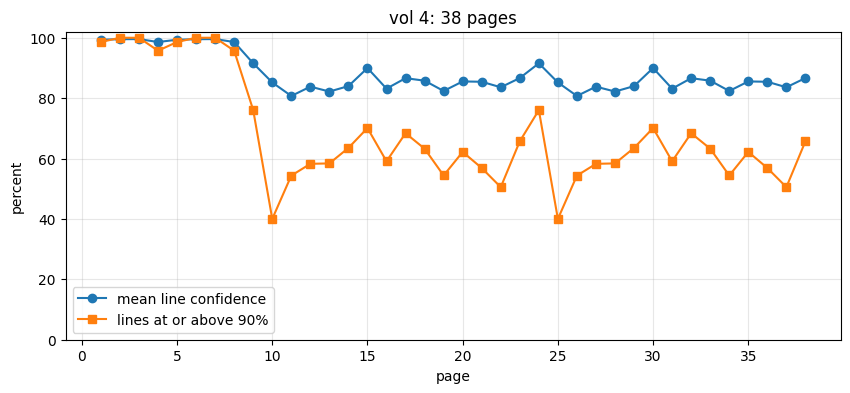

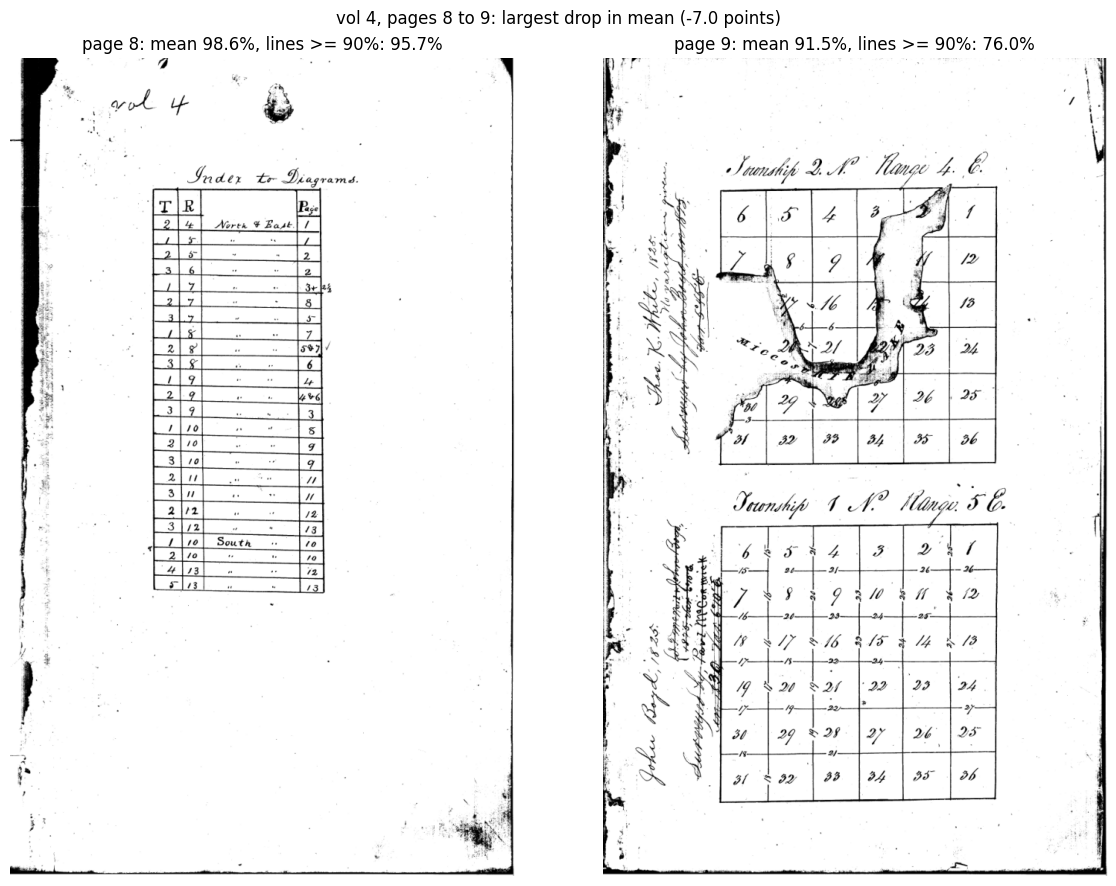

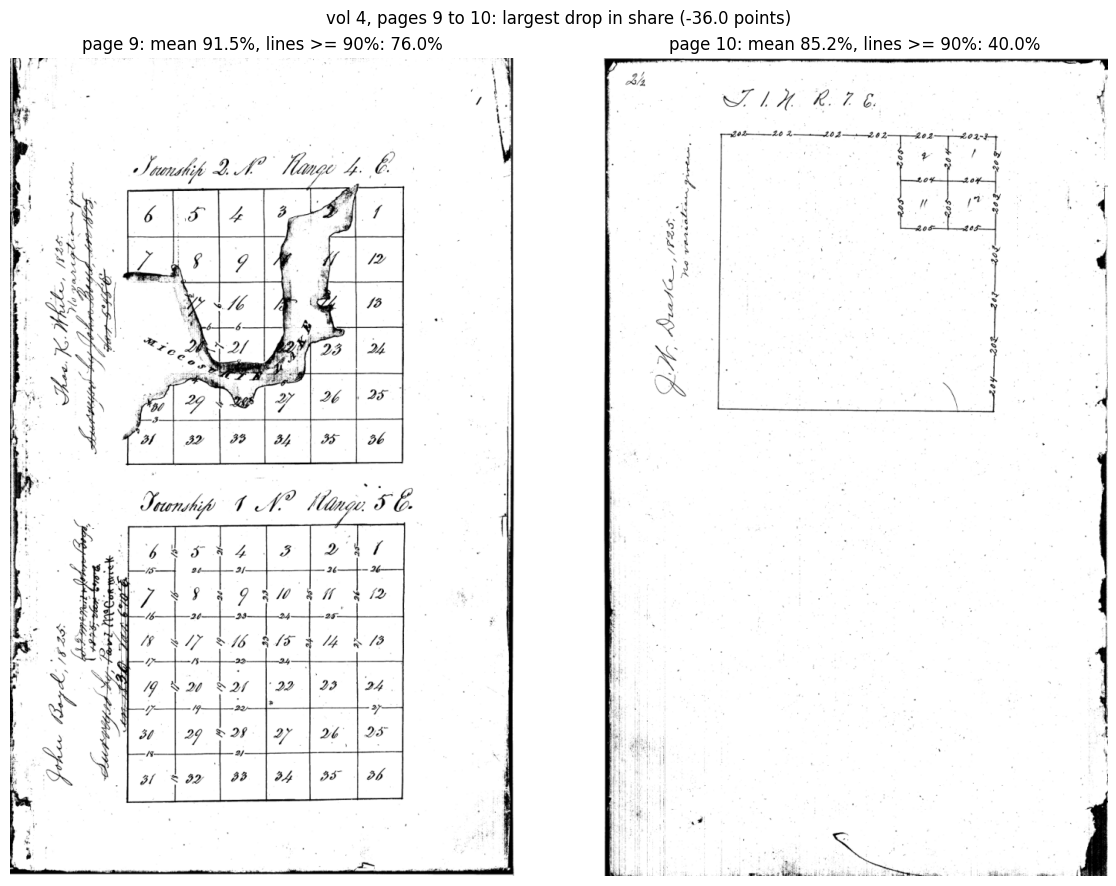

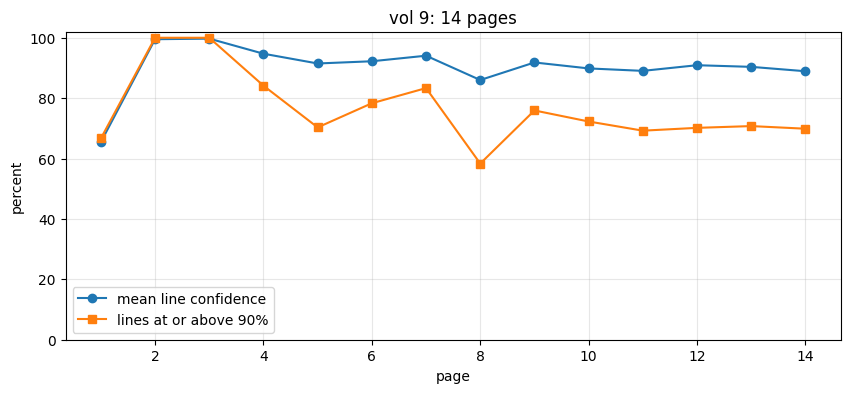

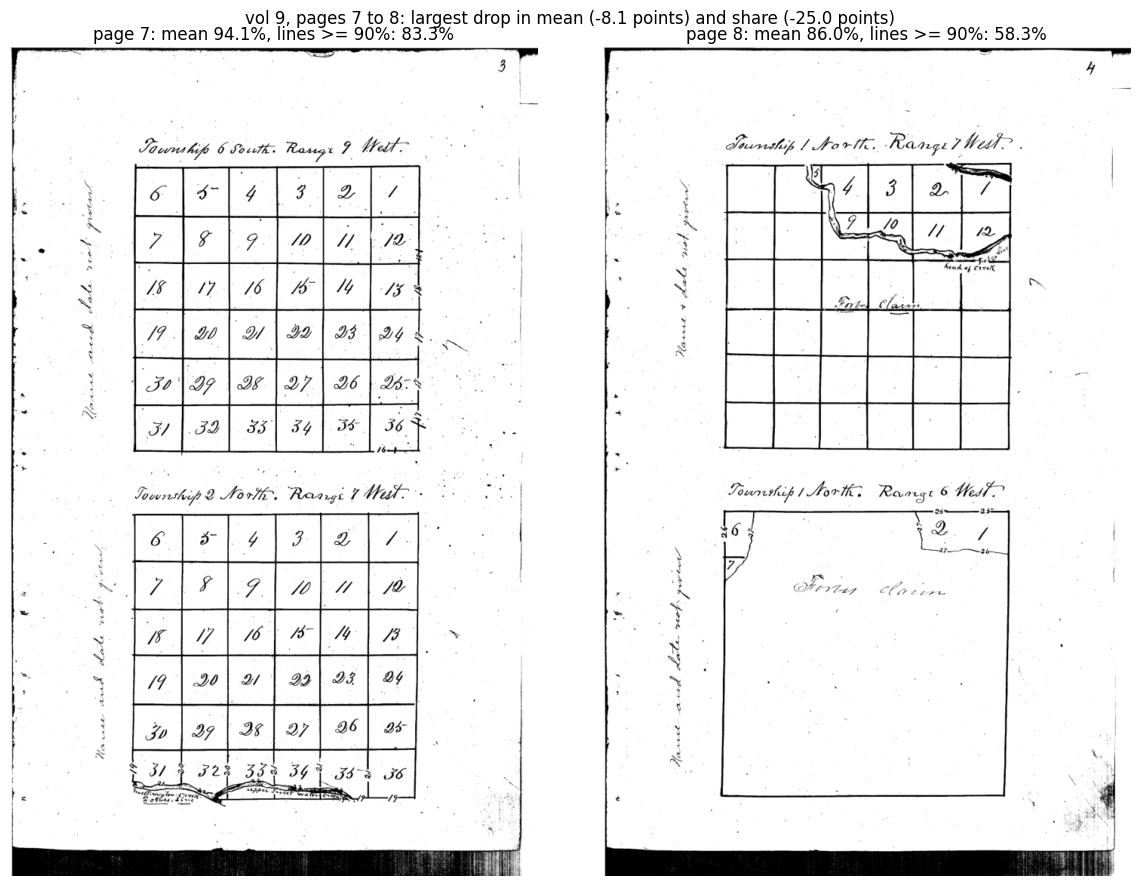

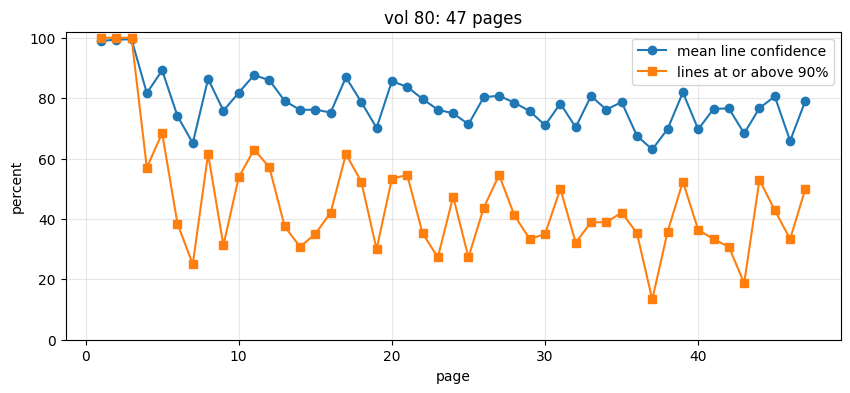

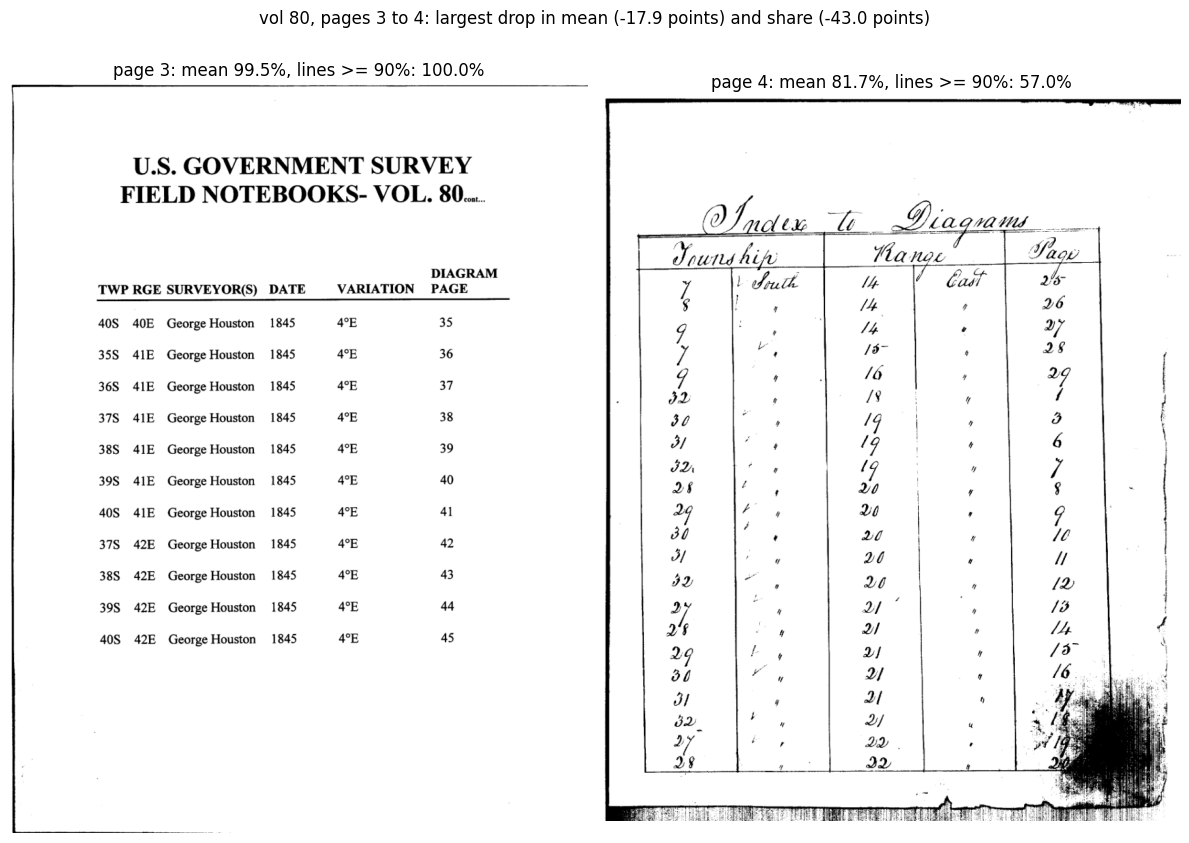

In [4]:
# setup
import json
import numpy as np
import pymupdf
import matplotlib.pyplot as plt
from pathlib import Path

# set dir
DATA_DIR = "/content/drive/MyDrive/armed-occupation-act/data"
IN_DIR = Path(DATA_DIR)
OUT_DIR = IN_DIR / "labins-ocr"

# config
VOLS = [4, 9, 80]
LINE_MIN = 0.90      # a line counts as confident at or above this score
SHOW_PX = 1100       # long side of displayed page in px

# helpers
def page_img(doc, i):
    zoom = SHOW_PX / max(doc[i].rect.width, doc[i].rect.height)
    pix = doc[i].get_pixmap(matrix=pymupdf.Matrix(zoom, zoom))
    return np.frombuffer(pix.samples, np.uint8).reshape(pix.height, pix.width, 3)

def page_stats(pages):
    mean, share = [], []
    for p in pages:
        s = np.array([l["score"] for l in p["lines"]], dtype=float)
        mean.append(s.mean() if len(s) else 0.0)                 # empty page scores 0
        share.append((s >= LINE_MIN).mean() if len(s) else 0.0)
    return np.array(mean), np.array(share)

# chart and largest sequential changes
for v in VOLS:
    pages = json.loads((OUT_DIR / f"vol{v:03d}.json").read_text(encoding="utf-8"))
    doc = pymupdf.open(IN_DIR / f"vol{v:03d}.pdf")
    mean, share = page_stats(pages)
    x = np.arange(1, len(pages) + 1)

    # line chart
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(x, mean * 100, marker="o", label="mean line confidence")
    ax.plot(x, share * 100, marker="s", label=f"lines at or above {LINE_MIN:.0%}")
    ax.set(xlabel="page", ylabel="percent", title=f"vol {v}: {len(pages)} pages", ylim=(0, 102))
    ax.legend()
    ax.grid(alpha=0.3)
    plt.show()
    if len(pages) < 2:
        continue

    # largest drop between consecutive pages, per metric
    jump = {"mean": int(np.argmin(np.diff(mean))), "share": int(np.argmin(np.diff(share)))}
    pairs = {}
    for m, i in jump.items():
        pairs.setdefault(i, []).append(m)        # same pair for both metrics is shown once

    # show pairs
    for i, ms in pairs.items():
        fig, axes = plt.subplots(1, 2, figsize=(12, 9))
        for ax, p in zip(axes, (i, i + 1)):
            ax.axis("off")
            ax.imshow(page_img(doc, p))
            ax.set_title(f"page {p+1}: mean {mean[p]*100:.1f}%, lines >= {LINE_MIN:.0%}: {share[p]*100:.1f}%")
        deltas = {"mean": (mean[i + 1] - mean[i]) * 100, "share": (share[i + 1] - share[i]) * 100}
        fig.suptitle(f"vol {v}, pages {i+1} to {i+2}: largest drop in " +
                     " and ".join(f"{m} ({deltas[m]:+.1f} points)" for m in ms))
        plt.tight_layout()
        plt.show()